In [4]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [1]:
# Importing necessary libraries for machine learning and data processing
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier #llamar random forest y xgboost (importar)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

In [ ]:
# 📌 2) Load your dataset
# Change this to the path of your file
file_path = r"" # <------------ Your path

#------------------Occidente Paths--------------------
#ResNet -> D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\Dataset\Occidente_Copy\ResNet50\Test_170626\HD_Combined.csv
#Autoencoders -> D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\venv\Autoencoders\Test_occidente\Autoencoders\features_encoder_occidente_V2.csv
#------- Guerrero Paths--------
#ResNet -> D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\Dataset\Guerrero\Color\Decimated_1506\ResNet50_Features\Combined\Guerrero_512x256_plus5.csv
#Autoencoders -> D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\venv\Autoencoders\Test_occidente\Autoencoders\features_encoder_Guerrero_V1_Color.csv

#Reading the CSV archive to check the vector numbers
df = pd.read_csv(file_path)
df.head(), df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Columns: 2051 entries, image_name to 2049
dtypes: float64(2048), int64(2), object(1)
memory usage: 929.5+ KB


(          image_name         0         1         2         3         4  \
 0   02.7-01808_a.png  0.092279  0.421532  0.256480  0.066770  0.126859   
 1  02.7-01814_o1.png  0.088438  0.195617  0.230953  0.140056  0.134886   
 2   02.7-01816_a.png  0.189534  0.348994  0.396709  0.076902  0.355681   
 3   02.7-01818_a.png  0.068343  0.206449  0.170251  0.090790  0.158984   
 4   02.7-01826_a.png  0.154739  0.190552  0.436602  0.088673  0.190513   
 
           5         6         7         8  ...      2040      2041      2042  \
 0  0.312822  0.433909  0.379835  0.853276  ...  0.445518  0.155493  0.145960   
 1  0.306852  0.206394  0.476397  0.463247  ...  0.268054  0.062941  0.071012   
 2  0.522292  0.379371  0.631182  0.737099  ...  0.178350  0.196751  0.080567   
 3  0.680077  0.431769  0.347562  0.731839  ...  0.342484  0.114115  0.148262   
 4  0.434263  0.359554  0.244556  0.675688  ...  0.379979  0.090663  0.052181   
 
        2043      2044      2045      2046      2047  2048  

In [193]:
# If your task is classification:

X = df.drop(columns=["image_name", "2048", "2049"]) # You can replace 'label_column' with the name of your target
y = df["2048"] #Iteramos con el cluster de KMeans, pero también se puede iterar con el cluster de Spectral Clustering

In [ ]:
#Counting the value of each class (How many examples does it have by class)
y.value_counts()

2048
1    16
2    10
3     6
6     6
4     5
5     5
7     5
8     5
Name: count, dtype: int64

In [ ]:
#Split the Dataset by:

#-------------Automatic Processing of Train and Test Sets----------------
#Split de imagenes en train y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



#--------------------Manual Processing of Train and Test Sets--------------------#
# columna_division = "2049"# 
# train_value = 0                 # 
# test_value = 1                         #
# df_train = df[df[columna_division] == train_value]
# df_test = df[df[columna_division] == test_value]


In [ ]:
#Coding to split Manual corpus

# X_train = df_train.drop(columns=["2048", "image_name", "2049"])
# y_train = df_train["2048"]

# X_test = df_test.drop(columns=["2048", "image_name", "2049"])
# y_test = df_test["2048"]


#----------------Check of Dimensions---------------
print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (46, 2048)
Dimensiones de X_test: (12, 2048)


In [ ]:
#Check that Y exists in a balanced distribution of classes
y_train.value_counts(), y_test.value_counts()

(2048
 1    12
 2     8
 6     5
 3     5
 5     4
 7     4
 8     4
 4     4
 Name: count, dtype: int64,
 2048
 1    4
 2    2
 7    1
 5    1
 3    1
 6    1
 8    1
 4    1
 Name: count, dtype: int64)

In [ ]:
# If you have categorical features, encode them:
#X = pd.get_dummies(X)

#Tranforming data in numbers Just for Xgboost

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [ ]:
# 5) Defining the Decision Tree, all of them considering a balanced class_weight.
dt = DecisionTreeClassifier(random_state=42, class_weight="balanced") 
rf = RandomForestClassifier(random_state=42, class_weight="balanced") 
xgb = XGBClassifier(random_state=42) 

In [ ]:
# 6) Hyperparameter grid (Not all of them are used to)

param_grid = {
    "criterion": ["gini", "entropy"],
    #"splitter": ["best", "random"],
    "max_depth": [2, 3, 4, 5, 6],
    "min_samples_split": [2, 4, 6],
    "max_features": ["sqrt", "log2"],
    "n_estimators": [3, 5, 10] #Use for random forest
    #'n_estimators': [50, 100, 200] #Use for xgboost
}

# param_grid = {
#     "criterion": ["gini", "entropy"],
#     "max_depth": [2, 6],
#     'ccp_alpha': [0.1, .01, .001],
#     "min_samples_split": [2, 4],
#     "min_samples_leaf": [1, 2, 4]
# }

In [231]:
# 7) Grid search setup
grid_search = GridSearchCV(
    estimator=rf, # Change this to dt or rf if you want to use Decision Tree or Random Forest
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
    
)

In [232]:
# 8) Fit GridSearchCV
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 180 candidates, totalling 900 fits


d:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\venv\venv\lib\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_split': [2, 4, ...], ...}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,10


In [36]:
# View the results of the grid search
results_df = pd.DataFrame(grid_search.cv_results_)
results_df

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_max_features,param_min_samples_split,param_splitter,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.016723,0.000000,0.016217,0.000000,gini,2,sqrt,2,best,"{'criterion': 'gini', 'max_depth': 2, 'max_fea...",0.15,0.15,0.210526,0.157895,0.210526,0.175789,0.028509,45
1,0.016723,0.000000,0.016217,0.000000,gini,2,sqrt,2,random,"{'criterion': 'gini', 'max_depth': 2, 'max_fea...",0.05,0.25,0.052632,0.157895,0.105263,0.123158,0.074755,110
2,0.016872,0.000121,0.009701,0.007921,gini,2,sqrt,4,best,"{'criterion': 'gini', 'max_depth': 2, 'max_fea...",0.15,0.15,0.210526,0.157895,0.210526,0.175789,0.028509,45
3,0.016971,0.000000,0.016070,0.000000,gini,2,sqrt,4,random,"{'criterion': 'gini', 'max_depth': 2, 'max_fea...",0.05,0.25,0.052632,0.157895,0.105263,0.123158,0.074755,110
4,0.013453,0.005992,0.012302,0.006244,gini,2,sqrt,6,best,"{'criterion': 'gini', 'max_depth': 2, 'max_fea...",0.15,0.15,0.210526,0.157895,0.210526,0.175789,0.028509,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,0.015201,0.003082,0.012258,0.003265,entropy,6,log2,2,random,"{'criterion': 'entropy', 'max_depth': 6, 'max_...",0.25,0.35,0.052632,0.157895,0.052632,0.172632,0.115293,52
116,0.016945,0.002114,0.010932,0.003069,entropy,6,log2,4,best,"{'criterion': 'entropy', 'max_depth': 6, 'max_...",0.25,0.05,0.315789,0.105263,0.315789,0.207368,0.110016,14
117,0.014127,0.003855,0.013903,0.003024,entropy,6,log2,4,random,"{'criterion': 'entropy', 'max_depth': 6, 'max_...",0.25,0.05,0.105263,0.210526,0.157895,0.154737,0.071575,74
118,0.015561,0.002865,0.014444,0.005767,entropy,6,log2,6,best,"{'criterion': 'entropy', 'max_depth': 6, 'max_...",0.20,0.10,0.210526,0.157895,0.157895,0.165263,0.039047,60


In [233]:
# 📌 9) Best params + score
print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)


Best parameters: {'criterion': 'entropy', 'max_depth': 3, 'max_features': 'log2', 'min_samples_split': 4, 'n_estimators': 10}
Best CV accuracy: 0.6244444444444444


In [ ]:
# 📌 10) Evaluate on test set
# best_model = grid_search.best_estimator_
# y_pred = best_model.predict(X)

In [222]:
# 10) Tomando en cuenta el test set <---- la versión anterior tomaba todos los valores.
best_model = grid_search.best_estimator_
# y_pred = best_model.predict(X_test)

In [234]:
#Retraining the model with the best hyperparameters found (best_model) to then evaluate on the test set.
best_model = grid_search.best_estimator_
best_model = best_model.fit(X_train, y_train)
#The Score of the model on the training set
best_model.score(X_train, y_train)

0.9782608695652174

In [235]:
best_model.score(X_test, y_test)

0.5833333333333334

In [225]:
#Volvemos a cargar esos parametros en y_pred para evaluar en el test set
y_pred = best_model.predict(X_test)

In [226]:
#Eva
best_model.score(X_test, y_test)
y_pred = best_model.predict(X_test)
# print("Test accuracy:", accuracy_score(y_test, y_pred))
# print(classification_report(y_test, y_pred))
# print(confusion_matrix(y_test, y_pred))

In [ ]:
#Printing results

print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Test accuracy: 0.6666666666666666
              precision    recall  f1-score   support

           1       0.67      1.00      0.80         4
           2       1.00      0.50      0.67         2
           3       0.00      0.00      0.00         1
           4       1.00      1.00      1.00         1
           5       0.00      0.00      0.00         1
           6       0.33      1.00      0.50         1
           7       1.00      1.00      1.00         1
           8       0.00      0.00      0.00         1

    accuracy                           0.67        12
   macro avg       0.50      0.56      0.50        12
weighted avg       0.58      0.67      0.59        12

[[4 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 1 0 0]]


d:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\venv\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\venv\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\venv\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

In [ ]:
#Creating ConfusionMatrix
import seaborn as sns
import matplotlib.pyplot as plt

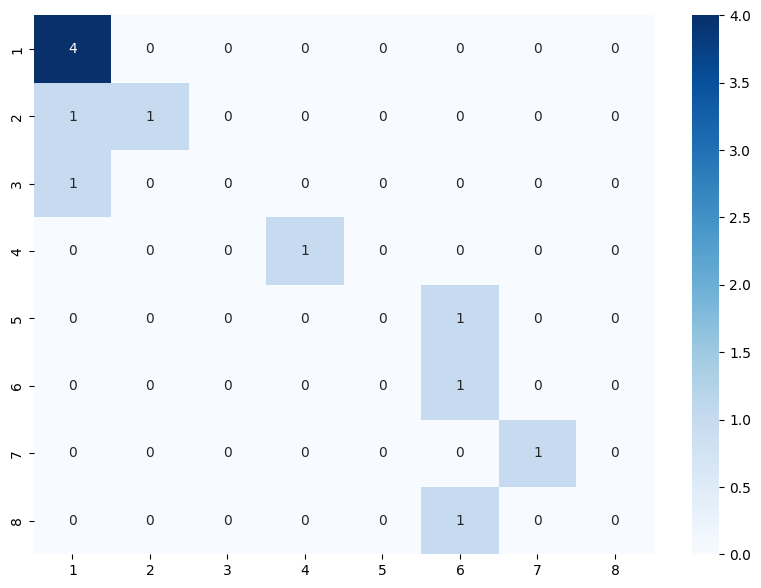

In [228]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.show()